# Measured-AND ripple arithmetic

Original four-T CCX replacement. This notebook executes bounded ideal-circuit checks; physical costs and formal proofs are separate. Use the full code package and its locked Python environment.

In [1]:
from pathlib import Path
import sys, json, os
ROOT = Path.cwd()
assert (ROOT / 'src/openquantum/shor_measured_and.py').is_file()
sys.path.insert(0, str(ROOT / 'src'))
from openquantum import shor_measured_and as measured
ARTIFACTS = Path(os.environ.get('OPENQUANTUM_AND_ARTIFACT_DIR', str(ROOT / 'assets/generated/shor/measured-and')))
width, a, b, carry = 2, 3, 1, 0
assert 1 <= width <= 3


## Circuit and complete counts

The helper is measured and conditionally cleared. Four T/Tdg gates replace each CCX; the additional measurement and controller work remain visible. Each classical wire is drawn separately to show reusable helper feedback and final data readout.

In [2]:
circuit = measured.build_addition_demo(width, a, b, carry)
counts = measured.logical_counts(circuit)
print(json.dumps(counts, indent=2))


{
  "logical_qubits": 6,
  "classical_bits": 6,
  "unconditional_primitive_counts": {
    "cx": 24,
    "h": 12,
    "measure": 9,
    "reset": 6,
    "sdg": 4,
    "t": 8,
    "tdg": 8,
    "x": 3
  },
  "all_one_feedback_extra_counts": {
    "cx": 4,
    "h": 8,
    "x": 4
  },
  "all_zero_feedback_primitive_count": 74,
  "all_one_feedback_primitive_count": 90,
  "literal_t_or_tdg": 16,
  "unlowered_phase_operations": 0,
  "classical_feedback_decisions": 4,
  "dependency_depth_all_zero_feedback": 55,
  "dependency_depth_all_one_feedback": 72,
  "depth_scope": "conservative serial source/decision dependency depth, not an optimized parallel DAG or physical cycles",
  "included": [
    "literal gates",
    "explicit preparation/reset",
    "measured helper",
    "conditional correction/clear",
    "requested final readout"
  ],
  "excluded_physical": [
    "code distance/factories",
    "routing/decoder",
    "calibrated measurement/reset/feedback faults and time",
    "P/CP synthesis i

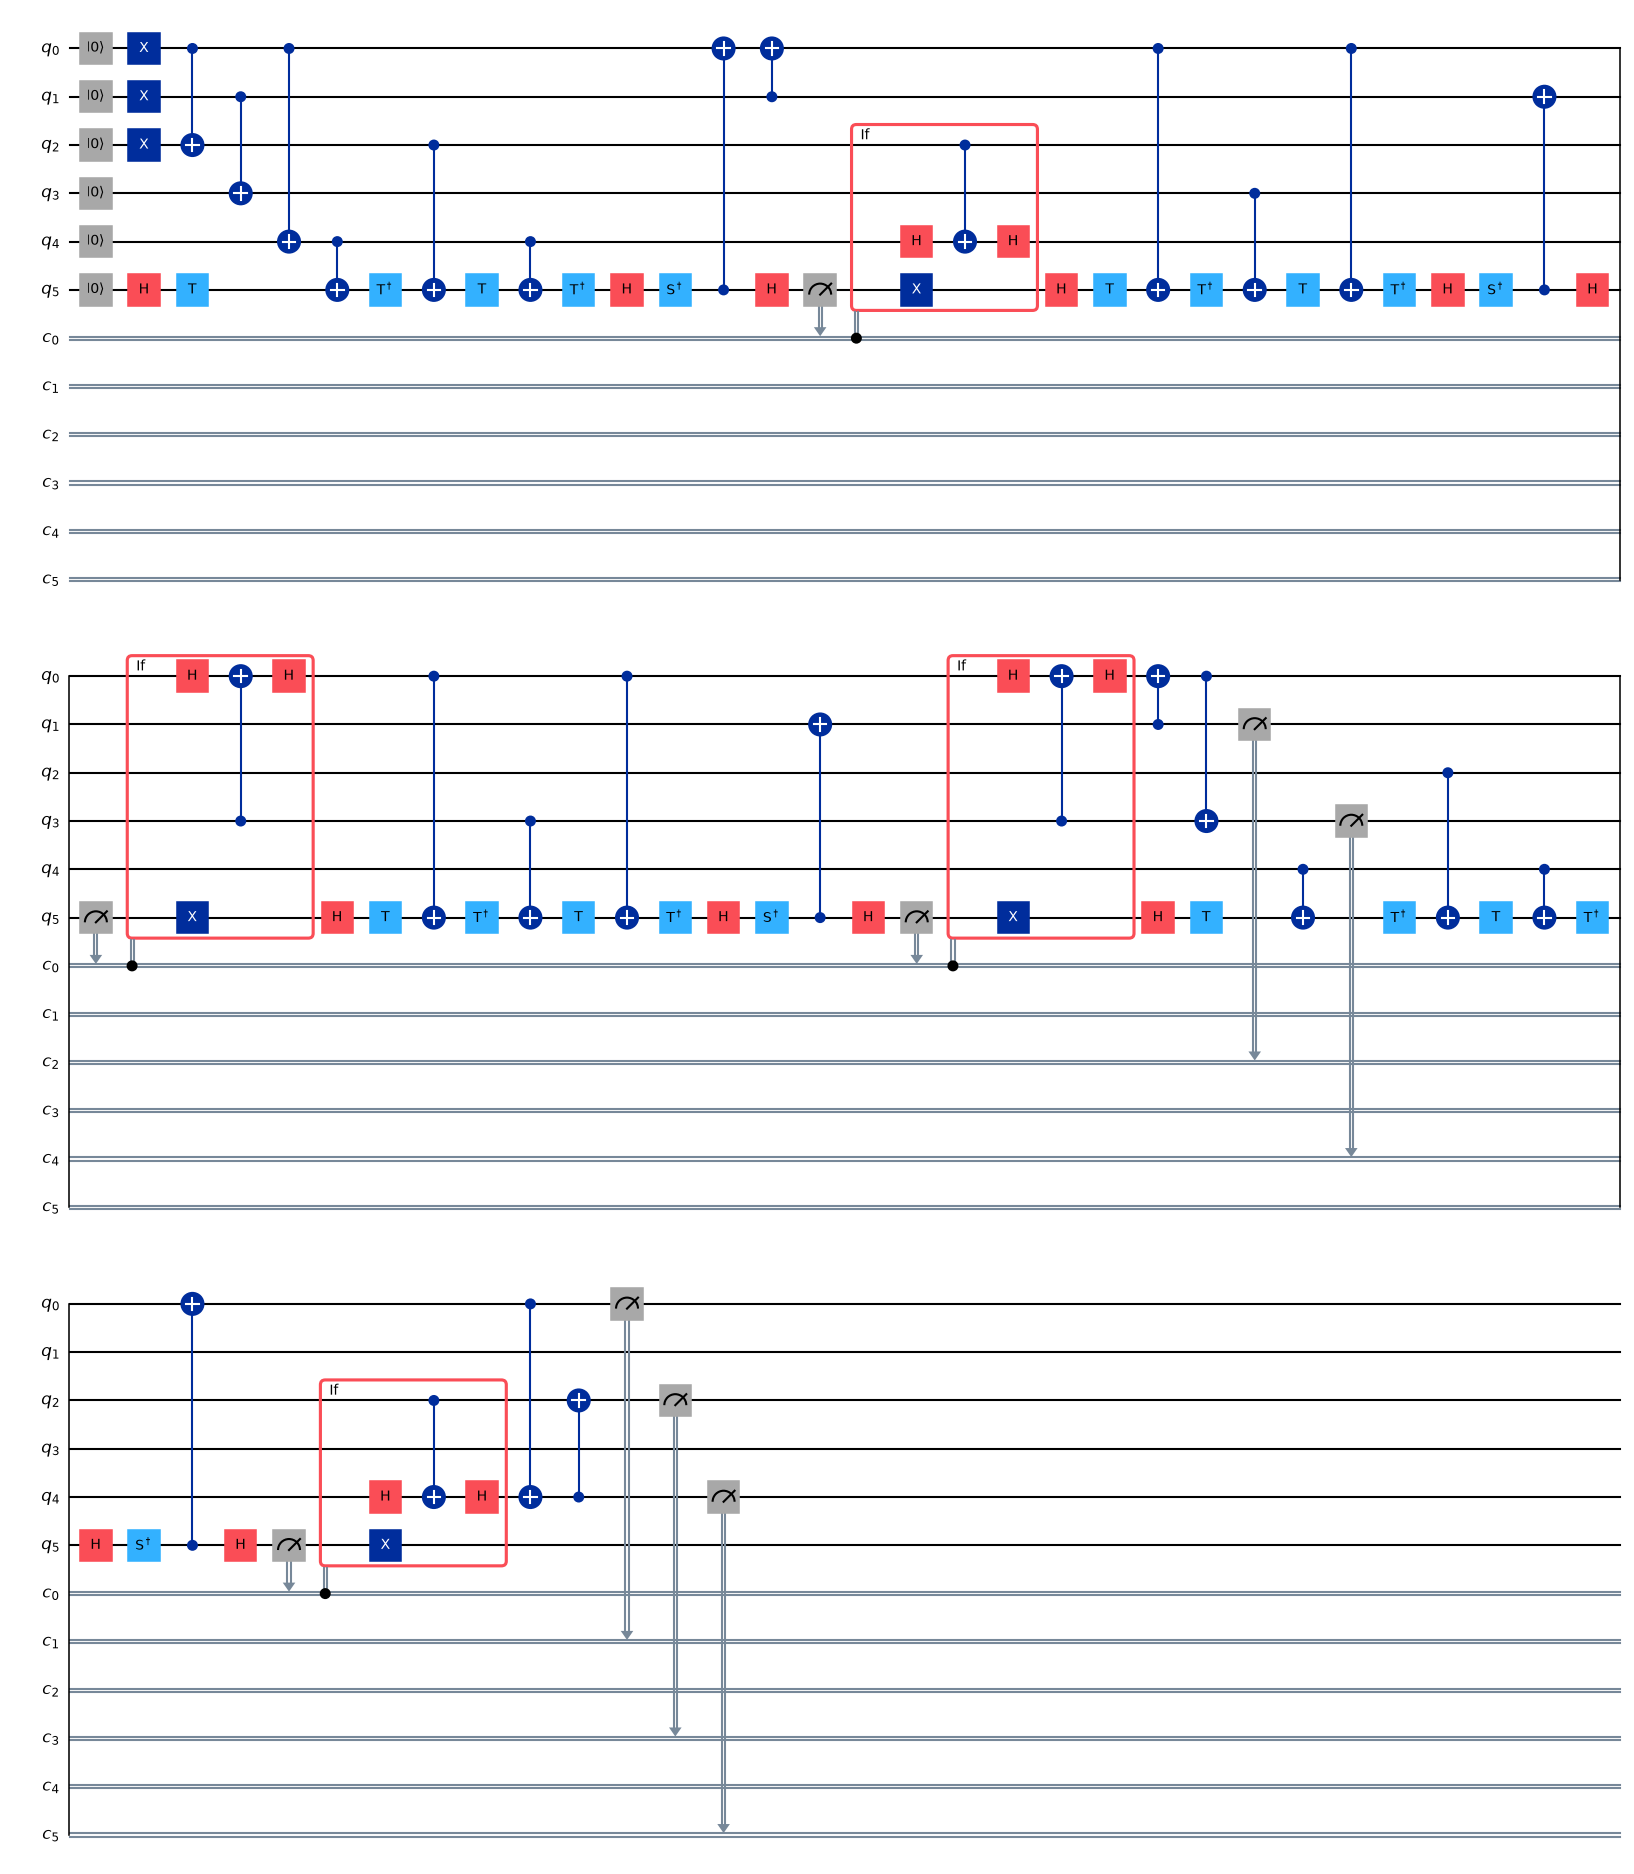

In [3]:
from IPython.display import display
import matplotlib.pyplot as plt
figure = circuit.draw(output='mpl', fold=32, scale=.75, cregbundle=False)
display(figure)
plt.close(figure)


In [4]:
result = measured.check_addition(width, a, b, carry)
print(json.dumps({'expected_output_basis': result['expected_output_basis'], 'max_density_error': result['max_density_error'], 'exact_sparse': result['exact_sparse']}, indent=2))


{
  "expected_output_basis": 3,
  "max_density_error": 3.774758283725532e-15,
  "exact_sparse": {
    "method": "actual primitive exact Q(zeta16) sparse interpretation; both branches checked before merging",
    "peak_amplitude_support": 3,
    "gate_state_applications": 153,
    "merged_uniform_feedback_pairs": 4,
    "norm_exactly_one": true,
    "amplitude_truncation": false,
    "terminal_measurements": 0,
    "formal_proof": false,
    "scope": "intended dyadic pi/8 logical-angle model recognized by exact Python spelling; not a binary-angle realization enclosure, general proof kernel or noise simulation"
  }
}


In [5]:
gadget = measured.gadget_checks()
print(json.dumps(gadget, indent=2))


{
  "kraus_columns": 8,
  "outcomes": 2,
  "max_kraus_error": 2.220446049250313e-16,
  "trace_preservation_error": 7.771561172376096e-16,
  "reference": "independent classical CCX permutation",
  "guarantee_scope": "bounded numerical all-data channel check; symbolic derivation separate",
  "physical_or_formal_certificate": false
}


## Retained order-finding and large-generator evidence

The study retains the separately executed small order-circuit checks and labels larger exports unvalidated. Reading these records is not another full quantum run.

In [6]:
import hashlib, stat

def bounded_bytes(path, limit):
    fd = os.open(path, os.O_RDONLY | os.O_NOFOLLOW | os.O_NONBLOCK)
    try:
        if not stat.S_ISREG(os.fstat(fd).st_mode):
            raise ValueError(f'bounded record must be regular: {path.name}')
        with os.fdopen(fd, 'rb', closefd=False) as handle:
            raw = handle.read(limit + 1)
    finally:
        os.close(fd)
    if len(raw) > limit:
        raise ValueError(f'bounded record exceeded: {path.name}')
    return raw

manifest = json.loads(bounded_bytes(ARTIFACTS / 'manifest.json', 131072))
if (manifest.get('schema') != 'openquantum-shor-measured-and-v1'
        or manifest.get('suite') is not True
        or manifest.get('simulate') is not True
        or manifest.get('status') != 'generated_scoped_checks'
        or manifest.get('physical_or_formal_claim') is not False):
    raise ValueError('retained study must be a checked full measured-AND suite')
source_paths = (
    'scripts/generate_shor_measured_and.py', 'src/openquantum/shor_measured_and.py',
    'src/openquantum/shor.py', 'src/openquantum/shor_ripple.py',
    'src/openquantum/__init__.py', 'src/openquantum/grover.py',
    'requirements-lock.txt', 'LICENSE',
)
current_sources = {}
for relative in source_paths:
    raw = bounded_bytes(ROOT / relative, 8388608)
    current_sources[relative] = {'bytes': len(raw), 'sha256': hashlib.sha256(raw).hexdigest()}
if manifest.get('source_files') != current_sources:
    raise ValueError('retained study source or environment lock differs from this package')
study_bytes = bounded_bytes(ARTIFACTS / 'study.json', 8388608)
study_identity = {'bytes': len(study_bytes), 'sha256': hashlib.sha256(study_bytes).hexdigest()}
if manifest['files'].get('study.json') != study_identity:
    raise ValueError('retained study byte count or hash differs from manifest')
study = json.loads(study_bytes)
if study.get('source_sha256') != current_sources:
    raise ValueError('retained study source identity differs from manifest')
if [(row.get('modulus'), row.get('base'), row.get('phase_bits'))
        for row in study['order_cases']] != [(15, 2, 4), (21, 2, 4)]:
    raise ValueError('retained suite does not contain the intended small order checks')
for row in study['order_cases']:
    if row['validation']['exact_sparse'].get('norm_exactly_one') is not True:
        raise ValueError('retained order check lacks its exact norm result')
print(json.dumps({'order_cases': study['order_cases'], 'generated_only': study['generated_only']}, indent=2))


{
  "order_cases": [
    {
      "modulus": 15,
      "base": 2,
      "phase_bits": 4,
      "validation": {
        "modulus": 15,
        "base": 2,
        "phase_bits": 4,
        "probabilities": [
          0.25,
          0.0,
          0.0,
          0.0,
          0.25,
          0.0,
          0.0,
          0.0,
          0.25,
          0.0,
          0.0,
          0.0,
          0.25,
          0.0,
          0.0,
          0.0
        ],
        "reference_probabilities": [
          0.25,
          4.686749320818307e-34,
          9.37349864163661e-34,
          4.218074388736474e-33,
          0.25,
          4.686749320818307e-34,
          9.37349864163661e-34,
          4.218074388736474e-33,
          0.25,
          4.686749320818307e-34,
          9.37349864163661e-34,
          4.218074388736474e-33,
          0.25,
          4.686749320818307e-34,
          9.37349864163661e-34,
          4.218074388736474e-33
        ],
        "max_probability_error": 4.2180

## Scaling and physical limits

Scalar formulas are not physical estimates. The measured source has extra initialization, feedback and readout; the current static estimator rejects this instrument.

In [7]:
for w in (1, 2, 3, 8, 24, 31):
    row = measured.addition_scaling(w)
    print(w, row['static']['literal_t_or_tdg'], row['measured_feedback_x']['literal_t_or_tdg'], row['physical_estimation_status'])


1 14 8 not computed
2 28 16 not computed
3 42 24 not computed
8 112 64 not computed
24 336 192 not computed
31 434 248 not computed


No mechanized proof, uniform floating enclosure, physical speedup or optimized 4w−4 Gidney adder is claimed. See the chapter for the full contracts and exclusions.